# P03 — Controle de qualidade como no sc-best-practices

## Regras do capítulo

Por amostra, sobre as métricas de `sc.pp.calculate_qc_metrics`:

| métrica | transformação | corte |
| --- | --- | --- |
| nº de UMIs | log1p | 5 MADs, dois lados |
| nº de genes | log1p | 5 MADs, dois lados |
| % dos UMIs nos 20 genes mais altos | — | 5 MADs, dois lados |
| fração mitocondrial | logit((mt + 1)/(n + 2)) | 3 MADs acima **e** % MT > 8 |

Ribossomais e hemoglobina são só diagnóstico. A diferença para o filtro do
notebook original (spatools, A01) é cortar os dois lados de contagens e
genes, usar o top-20 e a regra conjunta do MT.

## Duas versões dos limiares

Os candidatos agora incluem barcodes que o Cell Ranger não chamou (P01, P02),
e em algumas bibliotecas eles são muitos e de material nuclear. Calcular a
mediana sobre esse conjunto desloca os limiares para baixo e deixa passar o
que deveria sair. Por isso:

* **literal** — limiares calculados sobre todos os candidatos da biblioteca,
  como o capítulo faz sobre a matriz que recebe;
* **referência** — limiares calculados sobre as células do Cell Ranger e
  aplicados a todos os candidatos. É a versão usada adiante.

Uma regra a mais, fora do capítulo: barcodes com fração intrônica acima da
mediana + 5 MADs das células do Cell Ranger da biblioteca são tratados como
material nuclear (P01) e saem.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from functions import bpqc, config, fmt as F, io, plotting, qcplots
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)

NB = "P03_qc_best_practices"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK

## 1. Métricas e limiares

In [2]:
todos = io.load_data("P02_cellbender", "candidatos_todos")
todos["chamado"] = todos[["cellranger", "emptydrops", "cellbender"]].any(axis=1)
# métricas para todo barcode com ≥ 100 UMIs (chamado ou não): a seção 7 testa um piso único de UMIs

partes, thr_lit, thr_ref = [], {}, {}
for lib in LIBS:
    raw = io.read_raw(lib)
    t = todos[todos["library_id"] == lib].reset_index(drop=True)
    pos = pd.Index(raw["barcodes"]).get_indexer(t["barcode"])
    assert (pos >= 0).all()
    a = ad.AnnData(X=raw["X"][pos].astype(np.float32), obs=t.set_index("barcode"),
                   var=pd.DataFrame({"gene_symbol": raw["gene_names"]}, index=raw["gene_ids"]))
    obs = bpqc.qc_metrics(a)
    thr_lit[lib] = bpqc.thresholds(obs, ref=obs["chamado"].to_numpy())
    thr_ref[lib] = bpqc.thresholds(obs, ref=obs["cellranger"].to_numpy())
    fl = bpqc.flags(obs, thr_lit[lib]).add_prefix("lit_")
    fr = bpqc.flags(obs, thr_ref[lib]).add_prefix("ref_")
    cols = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo", "pct_counts_hb",
            "pct_counts_in_top_20_genes", "log1p_total_counts", "log1p_n_genes_by_counts", "logit_mt"]
    partes.append(pd.concat([t.set_index("barcode"), obs[cols], fl, fr], axis=1).reset_index())
    del raw, a
qc = pd.concat(partes, ignore_index=True)
qc["intronica_alta"], lim_intr = bpqc.intronic_flag(qc["frac_intronica"], qc["library_id"], qc["cellranger"])
qc["intronica_alta"] = qc["intronica_alta"].fillna(False).astype(bool)
qc["passa_lit"] = qc["lit_passa"] & ~qc["intronica_alta"] & qc["chamado"]
qc["passa_mad"] = qc["ref_passa"] & ~qc["intronica_alta"] & qc["chamado"]
# limites superiores de referência por linha (usados pelo padrão de valor único, seção 8)
for m_, col_ in (("umis", "log1p_total_counts"), ("genes", "log1p_n_genes_by_counts")):
    qc[f"ref_max_{m_}"] = qc["library_id"].map({l: thr_ref[l][m_][1] for l in LIBS})
qc["parece_celula"] = qc["parece_celula"].fillna(False).astype(bool)
qc_todos = qc
qc = qc_todos[qc_todos["chamado"]].copy()
tl = bpqc.thresholds_table(thr_lit).add_prefix("literal_")
tr = bpqc.thresholds_table(thr_ref).add_prefix("referencia_")
limiares = pd.concat([tr, tl], axis=1).reindex(LIBS)
limiares["intronica_max"] = lim_intr.reindex(LIBS)
io.save_table(limiares, NB, "limiares", description="Limiares do QC por biblioteca (escala original), referência e literal")
print(f"{F.n(len(qc_todos))} barcodes com ≥ 100 UMIs ou chamados; {F.n(len(qc))} chamados por pelo menos um método")
limiares.round(1)

88.154 barcodes com ≥ 100 UMIs ou chamados; 78.310 chamados por pelo menos um método


,referencia_umis_min,referencia_umis_max,referencia_genes_min,referencia_genes_max,referencia_top20_min,referencia_top20_max,referencia_mt_min,referencia_mt_max,literal_umis_min,literal_umis_max,literal_genes_min,literal_genes_max,literal_top20_min,literal_top20_max,literal_mt_min,literal_mt_max,intronica_max
library_id,,,,,,,,,,,,,,,,,
CTH92_NS,1703.6,57113.8,981.7,9917.4,3.5,30.0,NaN,5.3,1096.2,75754.2,660.7,12850.1,2.1,32.4,NaN,5.8,0.8
CTH92_ML,149.0,108852.4,229.3,14578.7,6.5,27.5,NaN,7.6,58.5,181363.8,115.6,21618.2,4.2,31.0,NaN,9.0,0.7
CTH94_NS,3760.6,37115.1,1881.0,7124.7,6.5,22.7,NaN,5.8,1638.5,66579.9,1176.6,9861.6,3.5,27.5,NaN,7.1,0.7
CTH94_ML,2153.8,59215.5,1070.7,10734.6,3.2,28.4,NaN,5.6,296.5,240344.0,267.7,28308.0,-4.9,40.8,NaN,8.6,0.8
CTH97_NS,2215.9,33195.0,983.5,8512.1,6.3,27.9,NaN,7.6,47.0,407.7,44.1,313.2,8.0,49.2,NaN,8.0,0.6
CTH97_ML,165.2,34706.6,168.8,6008.4,7.8,36.8,NaN,12.8,89.8,46038.2,91.7,8356.6,7.3,38.6,NaN,14.3,0.4
PB20_NS,1366.8,62175.4,422.0,16487.0,0.5,40.7,NaN,11.6,541.5,115213.5,171.3,27688.3,-1.3,45.0,NaN,13.3,0.9
PB20_ML,2207.8,47332.7,702.8,11874.0,4.1,36.4,NaN,8.0,1336.2,66882.4,432.0,15827.3,3.1,39.0,NaN,8.3,0.7
PB21_NS,2372.9,36224.9,819.1,9521.1,8.2,33.3,NaN,7.6,25.7,1942.6,29.2,1002.0,13.4,45.3,NaN,6.3,0.7


## 2. Quantas células passam

In [3]:
def conta(df, col):
    return df.groupby("library_id")[col].sum().reindex(LIBS).astype(int)


regras = ["umis", "genes", "top20", "mt"]
saida = pd.DataFrame({
    "candidatos": qc.groupby("library_id").size().reindex(LIBS),
    **{f"fora: {bpqc.LABELS[r]}": conta(qc, f"ref_fora_{r}") for r in regras},
    "fora: material nuclear": conta(qc, "intronica_alta"),
    "passam (referência)": conta(qc, "passa_mad"),
    "passam (literal)": conta(qc, "passa_lit"),
})
io.save_table(saida, NB, "saidas_por_regra", description="Candidatos reprovados por regra (limiares de referência) e aprovados")
por_metodo = pd.DataFrame({m: qc[qc[m]].groupby("library_id")["passa_mad"].agg(["size", "sum"]).reindex(LIBS)
                           .apply(lambda r: f"{F.n(r['sum'])} de {F.n(r['size'])}", axis=1)
                           for m in ["cellranger", "emptydrops", "cellbender"]})
io.save_table(por_metodo, NB, "aprovados_por_metodo", description="Barcodes que passam no QC, por método que os chamou")
display(saida)
por_metodo

,candidatos,fora: nº de UMIs,fora: nº de genes,fora: % nos 20 genes mais altos,fora: fração mitocondrial,fora: material nuclear,passam (referência),passam (literal)
library_id,,,,,,,,
CTH92_NS,957,121,131,42,24,1,822,839
CTH92_ML,1843,35,137,156,40,1,1629,1757
CTH94_NS,7803,2124,2129,1323,836,57,5581,5753
CTH94_ML,772,247,248,100,23,0,515,613
CTH97_NS,6751,5219,5210,3681,189,3623,1483,1376
CTH97_ML,5663,209,283,77,35,81,5273,5500
PB20_NS,770,131,118,12,14,0,636,678
PB20_ML,981,183,171,26,29,1,794,815
PB21_NS,25834,22128,22065,4574,204,15379,3652,6508


,cellranger,emptydrops,cellbender
library_id,,,
CTH92_NS,821 de 851,798 de 916,822 de 891
CTH92_ML,1.542 de 1.570,1.568 de 1.664,1.629 de 1.786
CTH94_NS,5.581 de 6.090,5.521 de 6.553,5.581 de 7.247
CTH94_ML,515 de 547,511 de 645,513 de 680
CTH97_NS,1.483 de 1.628,1.477 de 6.729,1.483 de 1.691
CTH97_ML,4.652 de 4.737,4.529 de 4.866,5.273 de 5.505
PB20_NS,607 de 635,556 de 667,636 de 684
PB20_ML,793 de 841,774 de 942,794 de 904
PB21_NS,3.652 de 4.266,3.623 de 25.612,3.652 de 22.847


In [4]:
qc["origem"] = np.select([qc["cellranger"], qc["emptydrops"] & qc["cellbender"], qc["emptydrops"], qc["cellbender"]],
                         ["Cell Ranger", "emptyDrops + CellBender", "só emptyDrops", "só CellBender"], default="")
rec = pd.crosstab(qc["origem"], qc["passa_mad"]).reindex(["Cell Ranger", "emptyDrops + CellBender", "só emptyDrops", "só CellBender"])
rec.columns = ["reprovados", "aprovados"]
rec["fração aprovada"] = rec["aprovados"] / rec.sum(axis=1)
io.save_table(rec, NB, "aprovados_por_origem", description="Aprovação no QC por origem da chamada")
ganho = qc[qc["passa_mad"] & ~qc["cellranger"]].groupby("library_id").size().reindex(LIBS).fillna(0).astype(int)
print("aprovados que o Cell Ranger não chamava, por biblioteca:",
      "; ".join(f"{l} {F.n(v)}" for l, v in ganho.items() if v))
rec

aprovados que o Cell Ranger não chamava, por biblioteca: CTH92_NS 1; CTH92_ML 87; CTH97_ML 621; PB20_NS 29; PB20_ML 1; MB34_ML 4


,reprovados,aprovados,fração aprovada
origem,,,
Cell Ranger,2970,34928,0.921632
emptyDrops + CellBender,18976,278,0.014439
só emptyDrops,18751,0,0.000000
só CellBender,1942,465,0.193187


## 3. Comparação com o filtro antigo (spatools, A01) nas células do Cell Ranger

In [5]:
a01 = io.load_data("A01_preprocessamento", "celulas_qc")[["library_id", "barcode", "passou_mad", "mantida"]]
cr = qc[qc["cellranger"]].merge(a01, on=["library_id", "barcode"], how="left")
assert cr["passou_mad"].notna().all()
comp = pd.crosstab(cr["passou_mad"].map({True: "passa no antigo", False: "sai no antigo"}),
                   cr["passa_mad"].map({True: "passa no novo", False: "sai no novo"}))
por_lib_comp = pd.DataFrame({
    "células do Cell Ranger": cr.groupby("library_id").size(),
    "passam no antigo (MAD k=5, spatools)": cr.groupby("library_id")["passou_mad"].sum(),
    "passam no novo (best practices)": cr.groupby("library_id")["passa_mad"].sum(),
    "saem só no novo": (~cr["passa_mad"] & cr["passou_mad"]).groupby(cr["library_id"]).sum(),
    "saem só no antigo": (cr["passa_mad"] & ~cr["passou_mad"]).groupby(cr["library_id"]).sum(),
}).reindex(LIBS)
io.save_table(por_lib_comp, NB, "antigo_vs_novo", description="Filtro antigo (spatools) × best practices nas células do Cell Ranger")
motivos = cr[~cr["passa_mad"] & cr["passou_mad"]][[f"ref_fora_{r}" for r in regras] + ["intronica_alta"]].sum()
print("células que o filtro novo remove e o antigo mantinha, por regra (uma célula pode ter mais de uma):",
      "; ".join(f"{k.replace('ref_fora_', '')} {int(v)}" for k, v in motivos.items()))
display(comp)
por_lib_comp

células que o filtro novo remove e o antigo mantinha, por regra (uma célula pode ter mais de uma): umis 292; genes 62; top20 98; mt 0; intronica_alta 136


passa_mad,passa no novo,sai no novo
passou_mad,,
passa no antigo,34611,515
sai no antigo,317,2455


,células do Cell Ranger,"passam no antigo (MAD k=5, spatools)",passam no novo (best practices),saem só no novo,saem só no antigo
library_id,,,,,
CTH92_NS,851,812,821,2,11
CTH92_ML,1570,1538,1542,7,11
CTH94_NS,6090,5579,5581,73,75
CTH94_ML,547,500,515,2,17
CTH97_NS,1628,1517,1483,34,0
CTH97_ML,4737,4696,4652,74,30
PB20_NS,635,602,607,1,6
PB20_ML,841,781,793,2,14
PB21_NS,4266,3666,3652,19,5


## 4. As distribuições com os limiares aplicados

Versão corrigida do `st.pl.outlier_quality` do notebook original: a mesma
ideia (distribuição por amostra com o limiar), mas o limiar desenhado é o
que foi aplicado, os dois lados aparecem quando os dois foram cortados, as
bibliotecas ficam em ordem de paciente com NS e ML lado a lado, e a % de
barcodes que sai por aquela regra vai escrita acima de cada uma.

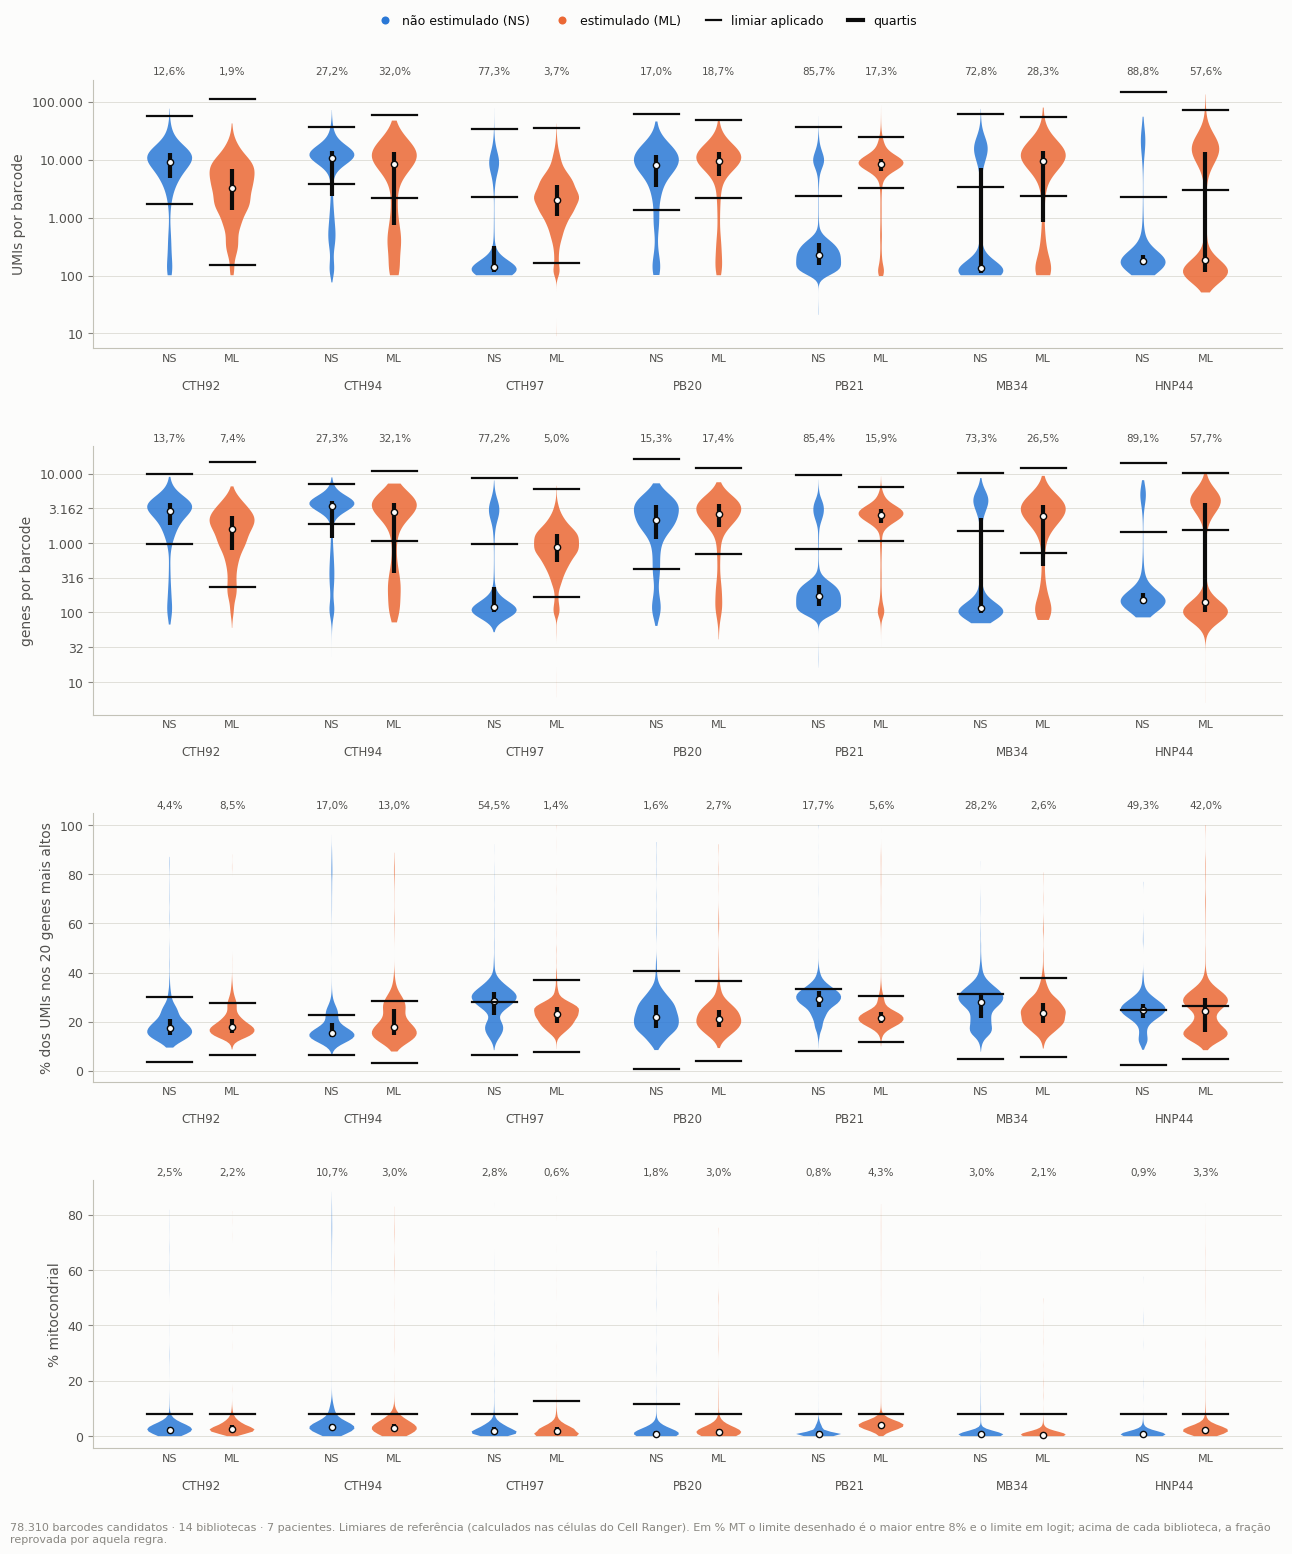

In [6]:
lim = bpqc.thresholds_table(thr_ref)
mt_max = np.maximum(config.BP_MT_PCT, lim["mt_max"])
paineis = [("total_counts", "UMIs por barcode", lim[["umis_min", "umis_max"]], True, "ref_fora_umis"),
           ("n_genes_by_counts", "genes por barcode", lim[["genes_min", "genes_max"]], True, "ref_fora_genes"),
           ("pct_counts_in_top_20_genes", "% dos UMIs nos 20 genes mais altos", lim[["top20_min", "top20_max"]], False,
            "ref_fora_top20"),
           ("pct_counts_mt", "% mitocondrial", pd.DataFrame({"min": np.nan, "max": mt_max}), False, "ref_fora_mt")]
fig, axes = plt.subplots(4, 1, figsize=(13, 15))
for ax, (col, ylab, l, log_, flag) in zip(axes, paineis):
    l = l.copy()
    l.columns = ["min", "max"]
    qcplots.outlier_quality(ax, qc, col, l, removed=qc.groupby("library_id")[flag].mean(), ylabel=ylab, log=log_)
qcplots.outlier_legend(fig, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.01))
plotting.note(fig, f"{F.n(len(qc))} barcodes candidatos · {plotting.N_DESIGN}. Limiares de referência (calculados nas células "
                   "do Cell Ranger). Em % MT o limite desenhado é o maior entre 8% e o limite em logit; acima de cada biblioteca, "
                   "a fração reprovada por aquela regra.", y=0.0)
fig.tight_layout(rect=(0, 0.01, 1, 0.98), h_pad=3)
plotting.savefig(fig, NB, "distribuicoes_e_limiares", description="Métricas de QC por biblioteca com os limiares aplicados",
                 data=lim.rename_axis("library_id").reset_index(), data_index=False)
plt.show()

## 5. Literal × referência, numa biblioteca com muito material nuclear

Os histogramas do capítulo, para PB21_NS, com os dois conjuntos de limiares.

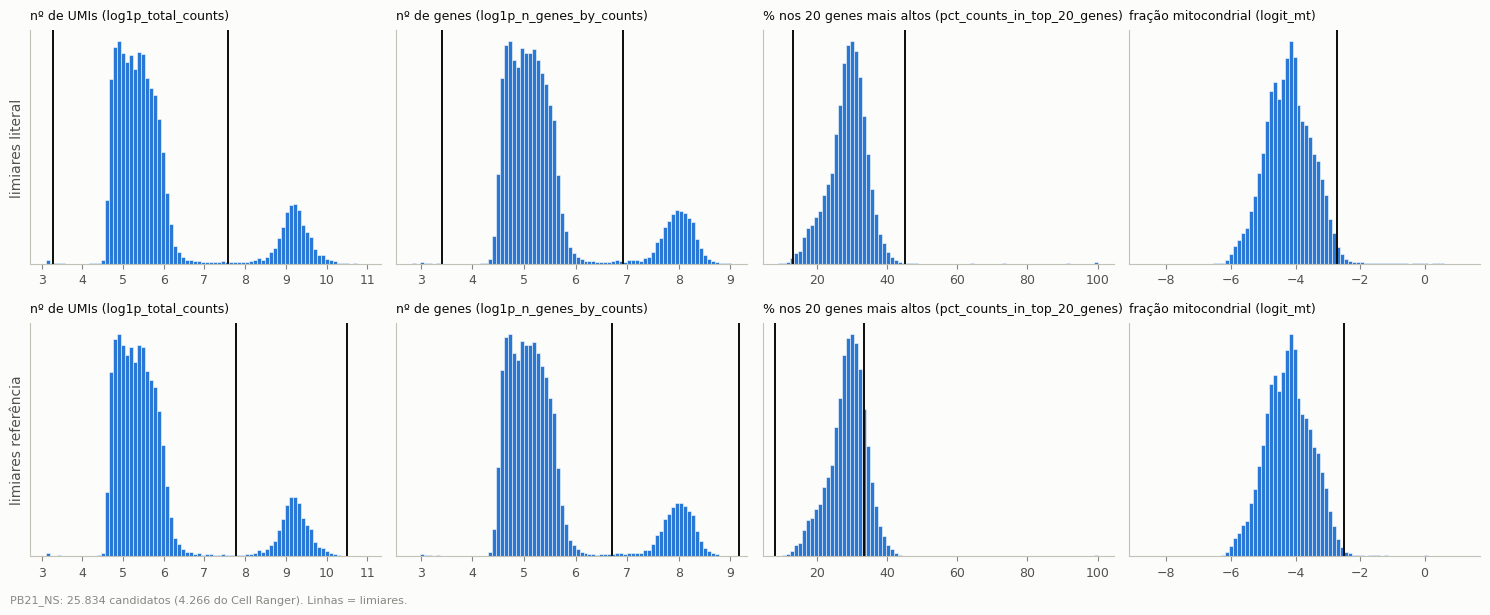

In [7]:
exemplo = "PB21_NS"
obs_ex = qc[qc["library_id"] == exemplo]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for row, (nome, thr) in enumerate([("literal", thr_lit[exemplo]), ("referência", thr_ref[exemplo])]):
    qcplots.threshold_histograms(axes[row], obs_ex, thr, bpqc.RULES, bpqc.LABELS)
    axes[row, 0].set_ylabel(f"limiares {nome}")
plotting.note(fig, f"{exemplo}: {F.n(len(obs_ex))} candidatos ({F.n(obs_ex['cellranger'].sum())} do Cell Ranger). Linhas = limiares.",
              y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "histogramas_pb21_ns", description="Histogramas das métricas com limiares literais e de referência, PB21_NS",
                 data=pd.DataFrame({k: [*thr_lit[exemplo][k], *thr_ref[exemplo][k]] for k in bpqc.RULES},
                                   index=["literal_min", "literal_max", "referencia_min", "referencia_max"])
                        .rename_axis("limite").reset_index(), data_index=False)
plt.show()

## 6. UMIs × genes antes e depois

A dispersão do capítulo, colorida por % MT, para três bibliotecas que
representam os casos: pequena (CTH92_NS), com material nuclear (PB21_NS) e
de baixa complexidade (CTH97_ML).

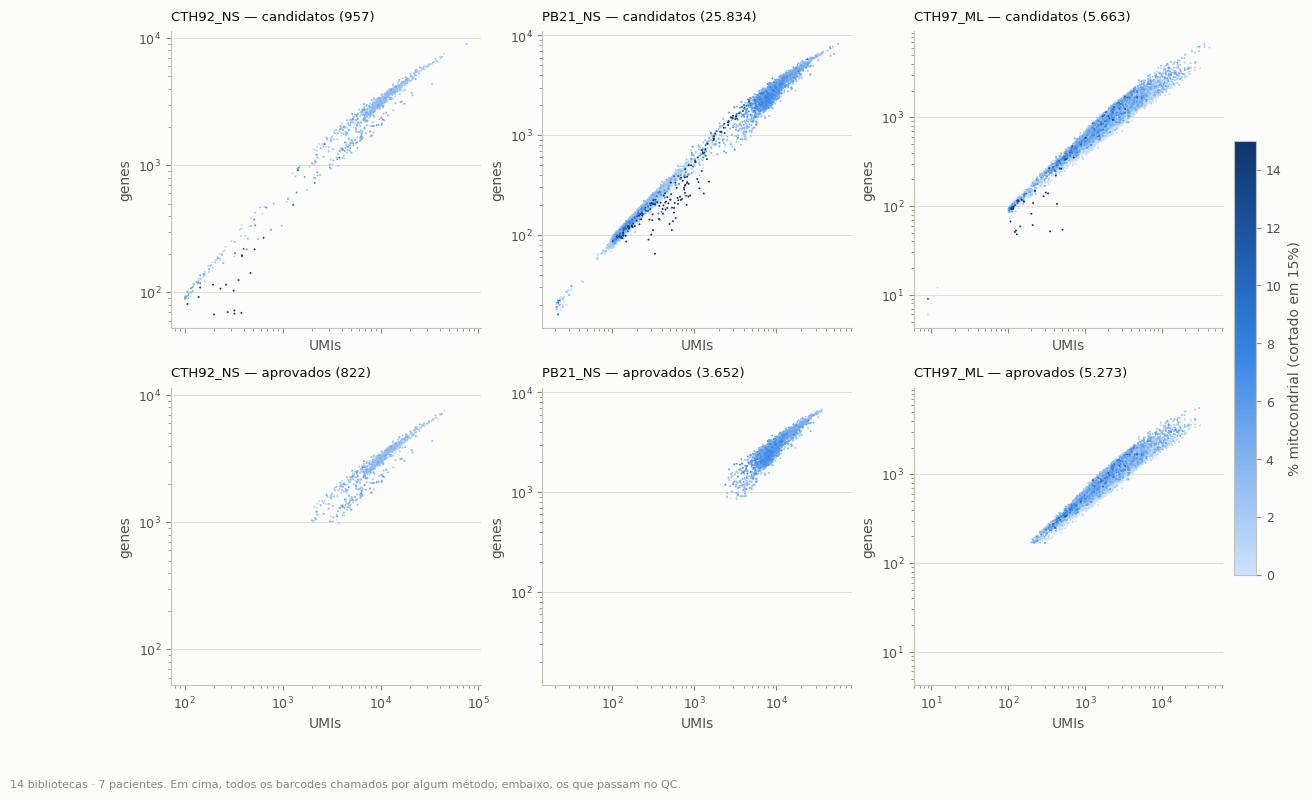

In [8]:
ex = ["CTH92_NS", "PB21_NS", "CTH97_ML"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5), sharex="col", sharey="col")
for j, lib in enumerate(ex):
    d = qc[qc["library_id"] == lib]
    for i, (nome, m) in enumerate([("candidatos", np.ones(len(d), bool)), ("aprovados", d["passa_mad"].to_numpy())]):
        s_ = qcplots.qc_scatter(axes[i, j], d["total_counts"][m], d["n_genes_by_counts"][m], d["pct_counts_mt"][m],
                                title=f"{lib} — {nome} ({F.n(m.sum())})")
cb = fig.colorbar(s_, ax=axes, fraction=0.02, pad=0.01)
cb.set_label("% mitocondrial (cortado em 15%)")
plotting.note(fig, f"{plotting.N_DESIGN}. Em cima, todos os barcodes chamados por algum método; embaixo, os que passam no QC.", y=0.0)
plotting.savefig(fig, NB, "umis_genes_mt", description="UMIs × genes colorido por % MT, antes e depois do QC",
                 data=saida.reset_index(), data_index=False)
plt.show()

## 7. Um piso único de UMIs para todas as amostras

Em vez de deixar cada método decidir quem é célula, um valor fixo: todo
barcode com pelo menos *P* UMIs entra como candidato, em todas as
bibliotecas, e passa pelo mesmo QC. O Cell Ranger usa *P* = 500. A pergunta é
se baixar (ou subir) esse valor muda o número de células **ao final** do
pré-processamento — e se o que entra a mais é célula.

Duas versões do QC, como antes:

* **referência** — limiares fixos, calculados nas células do Cell Ranger; o
  piso só decide quem é testado;
* **literal** — limiares recalculados sobre os candidatos de cada piso. É o
  que acontece quando o procedimento do capítulo é aplicado a uma matriz
  chamada com um piso mais baixo: os barcodes pobres entram na mediana e
  puxam o limiar inferior para baixo.

Para cada célula acrescentada em relação a *P* = 500, o teste de P01 diz se
o perfil dela é de célula (controle de profundidade, 1% de falsos positivos).

In [9]:
PISOS = [100, 150, 200, 250, 300, 400, 500, 750, 1000]
linhas = []
for lib in LIBS:
    d = qc_todos[qc_todos["library_id"] == lib]
    base = set(d.loc[(d["total_counts"] >= 500) & d["ref_passa"] & ~d["intronica_alta"], "barcode"])
    for piso in PISOS:
        c = d[d["total_counts"] >= piso]
        thr = bpqc.thresholds(c)
        lit = bpqc.flags(c, thr)["passa"] & ~c["intronica_alta"]
        ref = c["ref_passa"] & ~c["intronica_alta"]
        for nome, m in (("referência", ref), ("literal", lit)):
            fica = c[m.to_numpy()]
            extra = fica[~fica["cellranger"]]
            linhas.append({"library_id": lib, "piso": piso, "qc": nome, "candidatos": len(c), "finais": len(fica),
                           "do_cell_ranger": int(fica["cellranger"].sum()), "acrescentadas": len(extra),
                           "acrescentadas_com_perfil_de_celula": int(extra["parece_celula"].sum()),
                           "umis_medianos_acrescentadas": float(extra["total_counts"].median()) if len(extra) else np.nan})
pisos = pd.DataFrame(linhas)
io.save_table(pisos, NB, "piso_unico_por_biblioteca", index=False,
              description="Células finais por piso de UMIs, por biblioteca e versão do QC")
tot_p = pisos.groupby(["qc", "piso"])[["candidatos", "finais", "do_cell_ranger", "acrescentadas",
                                       "acrescentadas_com_perfil_de_celula"]].sum()
io.save_table(tot_p, NB, "piso_unico_total", description="Células finais por piso de UMIs, soma das bibliotecas")
tot_p

candidatos  finais  do_cell_ranger  acrescentadas  acrescentadas_com_perfil_de_celula
qc         piso                                                                                       
literal    100        88000   46458           27147          19311                                1351
           150        61447   37014           32137           4877                                 589
           200        53263   33754           31832           1922                                 337
           250        48593   33102           31847           1255                                 271
           300        45358   32849           31895            954                                 216
           400        41153   35892           35308            584                                  89
           500        39319   35504           35094            410                                   0
           750        37769   34932           34585            347                                   0
           1000       36841   34419           34123            296                                   0
referência 100        88000   35671           34928            743                                 227
           150        61447   35671           34928            743                                 227
           200        53263   35670           34928            742                                 226
           250        48593   35638           34928            710                                 201
           300        45358   35594           34928            666                                 170
           400        41153   35472           34928            544                                  89
           500        39319   35315           34928            387                                   0
           750        37769   34919           34579            340                                   0
           1000       36841   34489           34195            294                                   0

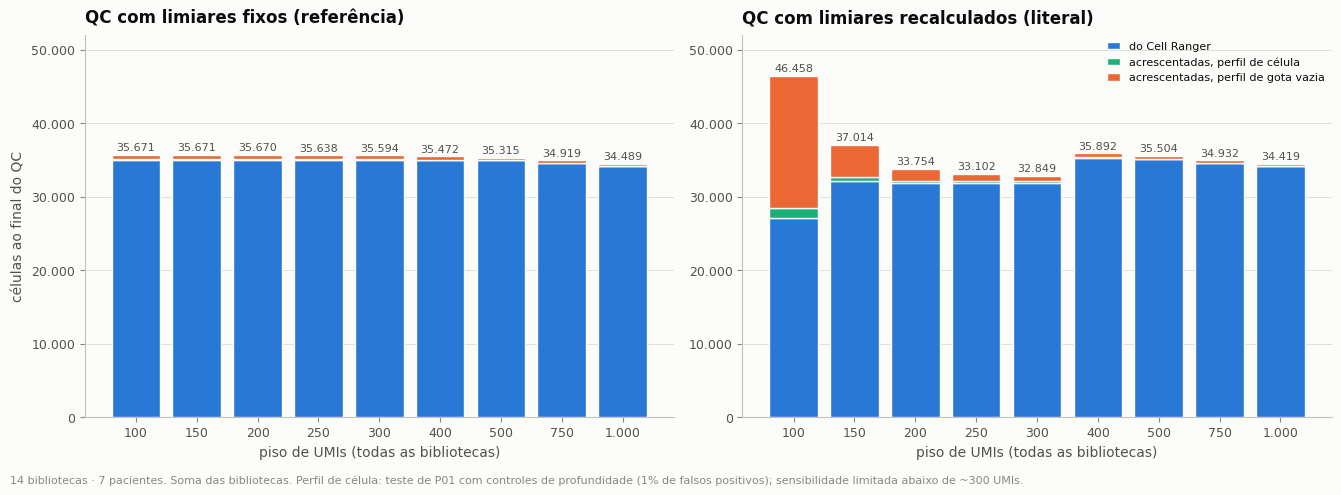

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=False)
for ax, nome in zip(axes, ["referência", "literal"]):
    t = tot_p.loc[nome]
    xs = np.arange(len(PISOS))
    cr_ = t["do_cell_ranger"].to_numpy()
    sim = t["acrescentadas_com_perfil_de_celula"].to_numpy()
    nao = (t["acrescentadas"] - t["acrescentadas_com_perfil_de_celula"]).to_numpy()
    ax.bar(xs, cr_, color=plotting.CATEGORICAL[0], edgecolor=INK["surface"], lw=1, label="do Cell Ranger", zorder=3)
    ax.bar(xs, sim, bottom=cr_, color=plotting.CATEGORICAL[2], edgecolor=INK["surface"], lw=1,
           label="acrescentadas, perfil de célula", zorder=3)
    ax.bar(xs, nao, bottom=cr_ + sim, color=plotting.CATEGORICAL[1], edgecolor=INK["surface"], lw=1,
           label="acrescentadas, perfil de gota vazia", zorder=3)
    for x, tt in zip(xs, t["finais"]):
        ax.annotate(F.n(tt), (x, tt), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK["secondary"])
    ax.set_xticks(xs)
    ax.set_xticklabels([F.n(p_) for p_ in PISOS])
    ax.set_xlabel("piso de UMIs (todas as bibliotecas)")
    ax.set_title(f"QC com limiares {'fixos (referência)' if nome == 'referência' else 'recalculados (literal)'}")
    plotting.thousands(ax, "y")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, tot_p["finais"].max() * 1.12)
axes[0].set_ylabel("células ao final do QC")
axes[1].legend(loc="upper right", fontsize=8)
plotting.note(fig, f"{plotting.N_DESIGN}. Soma das bibliotecas. Perfil de célula: teste de P01 com controles de profundidade "
                   "(1% de falsos positivos); sensibilidade limitada abaixo de ~300 UMIs.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "piso_unico", description="Células finais por piso de UMIs, com e sem limiares recalculados",
                 data=tot_p.reset_index(), data_index=False)
plt.show()

## Problemas encontrados

In [11]:
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       0
MINOR       0
INFO        0


severity,location,problem,evidence,impact,recommendation


## Conclusão

Com os limiares do capítulo calculados nas células do Cell Ranger, o QC
aprova 92% delas e quase nada do que os outros métodos acrescentam. O que
decide o número final é o limite inferior de 5 MADs por biblioteca, que vai
de ~150 a ~3.800 UMIs. O padrão adotado é um valor único de **200 UMIs** para
chamada e QC em todas as bibliotecas: as células do Cell Ranger entram se
passarem nas demais regras do capítulo; os barcodes de fora entram só se
tiverem perfil de célula (789, marcados como `baixa_profundidade`, mediana de
329 UMIs). Ao todo, 36.979 células antes dos doublets.

Duas armadilhas medidas aqui: recalcular os limiares sobre candidatos não
filtrados (o limite inferior desce, gotas vazias entram e células reais saem
como outliers superiores) e aplicar o teste de perfil às células do Cell
Ranger (reprovaria 8.753 células reais, 24%).

In [12]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

21 artefatos gravados por este notebook:
                        name    kind
                 valor_unico   table
  valor_unico_por_biblioteca   table
             fig_valor_unico  figure
             fig_valor_unico   table
               qc_candidatos parquet
                    limiares   table
            saidas_por_regra   table
        aprovados_por_metodo   table
        aprovados_por_origem   table
              antigo_vs_novo   table
fig_distribuicoes_e_limiares  figure
fig_distribuicoes_e_limiares   table
     fig_histogramas_pb21_ns  figure
     fig_histogramas_pb21_ns   table
           fig_umis_genes_mt  figure
           fig_umis_genes_mt   table
   piso_unico_por_biblioteca   table
            piso_unico_total   table
              fig_piso_unico  figure
              fig_piso_unico   table
                      issues   table


## 8. Um valor único para chamada e QC

A seção 7 mostra que o piso de chamada quase não pesa quando o QC usa os
limiares de referência: o que decide é o limite **inferior** do QC, 5 MADs
abaixo da mediana de cada biblioteca, que vai de ~150 UMIs (CTH92_ML,
CTH97_ML) a ~3.800 (CTH94_NS). Para padronizar um valor para todas as
amostras, testa-se um mínimo fixo de UMIs usado ao mesmo tempo como chamada
(todo barcode com pelo menos esse número) e como limite inferior do QC, no
lugar dos 5 MADs. As demais regras do capítulo continuam: limites superiores
de UMIs e genes, top-20 nos dois lados, MT em logit + 8%, e o filtro de
material nuclear.

In [13]:
resto = (qc_todos["log1p_total_counts"] <= qc_todos["ref_max_umis"]) & \
        (qc_todos["log1p_n_genes_by_counts"] <= qc_todos["ref_max_genes"]) & \
        ~qc_todos["ref_fora_top20"] & ~qc_todos["ref_fora_mt"] & ~qc_todos["intronica_alta"]
n_mad = int(qc_todos["passa_mad"].sum())
VALORES = [200, 300, 400, 500, 750, 1000, 1500, 2000]
linhas = []
for v in VALORES:
    d = qc_todos[(qc_todos["total_counts"] >= v) & resto]
    extra = d[~d["cellranger"]]
    linhas.append({"minimo_umis": v, "finais": len(d), "do_cell_ranger": int(d["cellranger"].sum()), "extras": len(extra),
                   "extras_com_perfil_de_celula": int(extra["parece_celula"].sum()),
                   "fracao_dos_extras_com_perfil": extra["parece_celula"].mean() if len(extra) else np.nan,
                   "diferenca_para_o_MAD": len(d) - n_mad})
unico = pd.DataFrame(linhas).set_index("minimo_umis")
io.save_table(unico, NB, "valor_unico", description="Mínimo fixo de UMIs para chamada e QC: células finais e perfil dos extras")
por_lib_unico = pd.DataFrame({f"≥ {v} UMIs": qc_todos[(qc_todos["total_counts"] >= v) & resto].groupby("library_id").size()
                              for v in (300, 500, 1000)})
por_lib_unico["MAD por biblioteca"] = qc_todos[qc_todos["passa_mad"]].groupby("library_id").size()
por_lib_unico["Cell Ranger"] = qc_todos[qc_todos["cellranger"]].groupby("library_id").size()
por_lib_unico = por_lib_unico.reindex(LIBS).fillna(0).astype(int)
io.save_table(por_lib_unico, NB, "valor_unico_por_biblioteca", description="Células finais por biblioteca com mínimos fixos e com o MAD")
display(unico.round(3))
por_lib_unico

,finais,do_cell_ranger,extras,extras_com_perfil_de_celula,fracao_dos_extras_com_perfil,diferenca_para_o_MAD
minimo_umis,,,,,,
200,39544,36190,3354,789,0.235,3873
300,37936,36190,1746,471,0.270,2265
400,37364,36190,1174,230,0.196,1693
500,36940,36190,750,17,0.023,1269
750,36162,35555,607,9,0.015,491
1000,35514,35015,499,8,0.016,-157
1500,34265,33997,268,2,0.007,-1406
2000,33236,33129,107,2,0.019,-2435


,≥ 300 UMIs,≥ 500 UMIs,≥ 1000 UMIs,MAD por biblioteca,Cell Ranger
library_id,,,,,
CTH92_NS,860,852,842,822,851
CTH92_ML,1628,1587,1460,1629,1570
CTH94_NS,6050,5959,5824,5581,6090
CTH94_ML,615,590,552,515,547
CTH97_NS,1563,1534,1510,1483,1628
CTH97_ML,5199,4959,4260,5273,4737
PB20_NS,687,677,649,636,635
PB20_ML,860,835,821,794,841
PB21_NS,4038,3834,3743,3652,4266


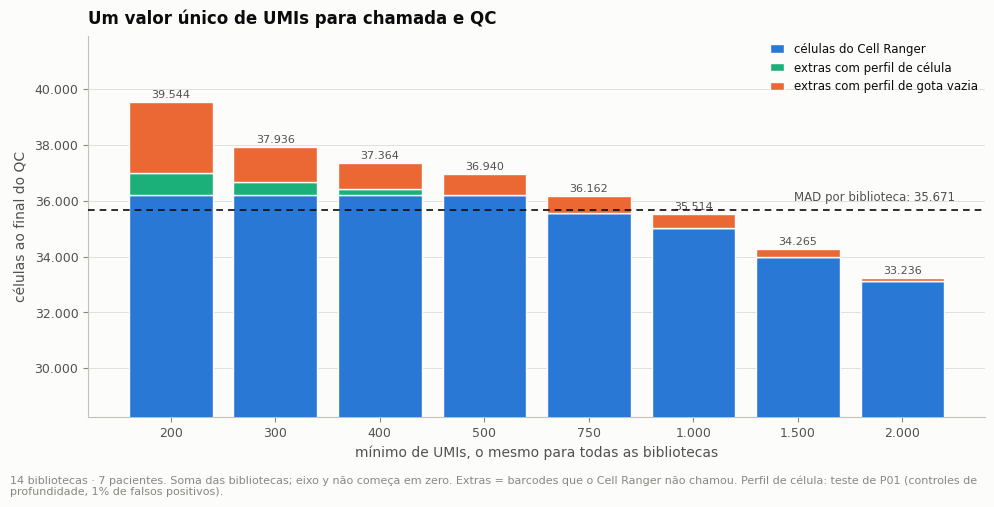

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.8))
xs = np.arange(len(VALORES))
cr_ = unico["do_cell_ranger"].to_numpy()
sim = unico["extras_com_perfil_de_celula"].to_numpy()
nao = (unico["extras"] - unico["extras_com_perfil_de_celula"]).to_numpy()
ax.bar(xs, cr_, color=plotting.CATEGORICAL[0], edgecolor=INK["surface"], lw=1, label="células do Cell Ranger", zorder=3)
ax.bar(xs, sim, bottom=cr_, color=plotting.CATEGORICAL[2], edgecolor=INK["surface"], lw=1, label="extras com perfil de célula", zorder=3)
ax.bar(xs, nao, bottom=cr_ + sim, color=plotting.CATEGORICAL[1], edgecolor=INK["surface"], lw=1,
       label="extras com perfil de gota vazia", zorder=3)
ax.axhline(n_mad, color=INK["primary"], lw=1.2, ls=(0, (4, 3)), zorder=4)
ax.annotate(f"MAD por biblioteca: {F.n(n_mad)}", (len(VALORES) - 0.5, n_mad), xytext=(0, 4), textcoords="offset points",
            ha="right", va="bottom", fontsize=8.5, color=INK["secondary"])
for x, t_ in zip(xs, unico["finais"]):
    ax.annotate(F.n(t_), (x, t_), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8, color=INK["secondary"])
ax.set_xticks(xs)
ax.set_xticklabels([F.n(v) for v in VALORES])
ax.set_xlabel("mínimo de UMIs, o mesmo para todas as bibliotecas")
ax.set_ylabel("células ao final do QC")
plotting.thousands(ax, "y")
ax.set_ylim(unico["finais"].min() * 0.85, unico["finais"].max() * 1.06)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", fontsize=8.5)
ax.set_title("Um valor único de UMIs para chamada e QC")
plotting.note(fig, f"{plotting.N_DESIGN}. Soma das bibliotecas; eixo y não começa em zero. Extras = barcodes que o Cell Ranger "
                   "não chamou. Perfil de célula: teste de P01 (controles de profundidade, 1% de falsos positivos).", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "valor_unico", description="Células finais por mínimo fixo de UMIs, com o perfil dos extras",
                 data=unico.reset_index(), data_index=False)
plt.show()

### O padrão adotado

**200 UMIs** para todas as bibliotecas, como chamada e como mínimo do QC, no
lugar dos 5 MADs por biblioteca. As demais regras do capítulo continuam
(limites superiores, top-20, MT em logit + 8%, sem material nuclear).

* **Células do Cell Ranger** entram se passarem nessas regras.
* **Barcodes que o Cell Ranger não chamou** (200–500 UMIs, quase todos) só
  entram se o teste de P01 disser que o perfil é de célula; abaixo de 500 a
  maior parte tem perfil de gota vazia. Ficam marcados como `baixa_profundidade`
  para poderem ser excluídos em análises que dependam de contagens (DE,
  citocinas).
* O teste de perfil **não** é aplicado às células do Cell Ranger: ele foi
  calibrado na profundidade dos barcodes extras (~150 UMIs) e compara cada
  barcode com o perfil médio da biblioteca. Em células profundas, ele passa a
  penalizar estados diferentes da média — a célula abaixo mostra quantas
  células reais ele tiraria.

`passa` é esse padrão; `passa_mad` (MAD por biblioteca) fica para comparação.

In [15]:
cel_like = qc_todos["parece_celula"].fillna(False).astype(bool)
base = (qc_todos["total_counts"] >= config.QC_MIN_UMIS) & resto
qc_todos["passa"] = base & (qc_todos["cellranger"] | cel_like)
qc_todos["baixa_profundidade"] = qc_todos["passa"] & ~qc_todos["cellranger"]
cr_reprovadas = base & qc_todos["cellranger"] & ~cel_like
print(f"padrão de {config.QC_MIN_UMIS} UMIs: {F.n(qc_todos['passa'].sum())} células (MAD por biblioteca: {F.n(n_mad)}); "
      f"{F.n(qc_todos['baixa_profundidade'].sum())} de baixa profundidade, fora do Cell Ranger, com mediana de "
      f"{F.n(qc_todos.loc[qc_todos['baixa_profundidade'], 'total_counts'].median())} UMIs e "
      f"{F.n(qc_todos.loc[qc_todos['baixa_profundidade'], 'n_genes_by_counts'].median())} genes")
print(f"se o teste de perfil valesse também para as células do Cell Ranger, sairiam {F.n(cr_reprovadas.sum())} "
      f"({F.pct(cr_reprovadas.sum() / (base & qc_todos['cellranger']).sum(), 0)}), com mediana de "
      f"{F.n(qc_todos.loc[cr_reprovadas, 'total_counts'].median())} UMIs — células reais, não gotas vazias")
pad = pd.DataFrame({"Cell Ranger": qc_todos[qc_todos["cellranger"]].groupby("library_id").size(),
                    "padrão: do Cell Ranger": qc_todos[qc_todos["passa"] & qc_todos["cellranger"]].groupby("library_id").size(),
                    "padrão: baixa profundidade": qc_todos[qc_todos["baixa_profundidade"]].groupby("library_id").size(),
                    "MAD por biblioteca": qc_todos[qc_todos["passa_mad"]].groupby("library_id").size()}).reindex(LIBS).fillna(0).astype(int)
io.save_table(pad, NB, "padrao_por_biblioteca", description="Padrão de 200 UMIs por biblioteca: células do Cell Ranger e de baixa profundidade")
io.save_data(qc_todos, NB, "qc_candidatos",
             description="Métricas e regras de QC de todo barcode com ≥ 100 UMIs ou chamado; 'passa' = padrão de 200 UMIs "
                         "(extras só com perfil de célula), 'passa_mad' = MAD por biblioteca")
pad

padrão de 200 UMIs: 36.979 células (MAD por biblioteca: 35.671); 789 de baixa profundidade, fora do Cell Ranger, com mediana de 329 UMIs e 254 genes
se o teste de perfil valesse também para as células do Cell Ranger, sairiam 8.753 (24%), com mediana de 7.397 UMIs — células reais, não gotas vazias
[io] conteúdo mudou — nova versão: qc_candidatos__v4.parquet (anterior preservada)


,Cell Ranger,padrão: do Cell Ranger,padrão: baixa profundidade,MAD por biblioteca
library_id,,,,
CTH92_NS,851,845,21,822
CTH92_ML,1570,1542,50,1629
CTH94_NS,6090,5867,100,5581
CTH94_ML,547,535,10,515
CTH97_NS,1628,1533,33,1483
CTH97_ML,4737,4652,197,5273
PB20_NS,635,628,8,636
PB20_ML,841,829,21,794
PB21_NS,4266,3832,81,3652
